# Встреча 3. Запуск и доверие к данным

**Легенда.** Тест нового чекаута отработал 14 дней по дизайн-доку встречи 2: сплит 80/20, около 105 тыс. пользователей. Владелец продукта ждёт эффект. Но сначала надо ответить на другой вопрос: можно ли верить данным? Платформа могла нечестно раздать группы, потерять события или записать пользователя дважды. Сломанный сплит даёт «эффект», которого нет, или прячет настоящий, и никакая статистика после этого не спасёт.

Параллельно платформа прислала пять тестов других команд с тревогой SRM и тест виджета доставки, где «что-то не так с событиями». Итог встречи — очищенные данные чекаута и чек-лист запуска `launch_checklist.md`, по которому команда будет проверять каждый следующий тест.

Встреча опирается на книгу Kohavi R., Tang D., Xu Y. *Trustworthy Online Controlled Experiments* (гл. 3 и 21), разбор причин SRM из Fabijan A. et al. (KDD 2019), ловушки метрик из Dmitriev P. et al. (KDD 2017) и анализ по триггеру из Deng A., Hu V. (WSDM 2015).

**Разделы**

1. Сплитование: хеш и соль.
2. Как ломается сплит.
3. Качество выгрузки чекаута.
4. SRM: доли групп против плана.
5. A/A по солям и мощность SRM.
6. SRM-детектив: пять выгрузок — пять причин.
7. Как SRM смещает эффект.
8. Телеметрия и триггеринг.
9. Тест виджета доставки.
10. Guardrail на старте.
11. Чек-лист запуска и данные для встречи 6.
12. Итоги.

По ходу встречаются вопросы для обсуждения: сначала подумайте и обсудите, потом раскройте ответ.

### Библиотеки и функции

In [1]:
import hashlib
import zlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

BLUE, RED, GREEN, GRAY, ORANGE = '#4C72B0', '#C44E52', '#55A868', '#7F7F7F', '#DD8452'
DATA = Path('../data')
SALT, SHARE_B = 'checkout-v2', 0.20


def assign_group(user_id, salt: str = SALT, share_b: float = SHARE_B) -> str:
    """Назначение группы платформой: md5(соль:user_id) → бакет 0..9999 → B, если бакет < 2000."""
    h = int(hashlib.md5(f'{salt}:{user_id}'.encode()).hexdigest(), 16)
    return 'B' if h % 10_000 < share_b * 10_000 else 'A'


def md5_hash(ids, salt: str) -> np.ndarray:
    """MD5 строки 'соль:id' → целое (первые 15 hex-символов)."""
    return np.array([int(hashlib.md5(f'{salt}:{i}'.encode()).hexdigest()[:15], 16) for i in ids], dtype=np.int64)


def crc32_hash(ids, salt: str) -> np.ndarray:
    return np.array([zlib.crc32(f'{salt}:{i}'.encode()) for i in ids], dtype=np.int64)


def java_hash(ids, salt: str) -> np.ndarray:
    """Java String.hashCode() строки 'соль:id' (32 бита, беззнаково), векторно для id одной длины."""
    mask = np.uint64(0xFFFFFFFF)
    value = np.uint64(0)
    for ch in f'{salt}:'.encode():
        value = (value * np.uint64(31) + np.uint64(ch)) & mask
    value = np.full(len(ids), value, dtype=np.uint64)
    digits = np.array([list(s) for s in np.char.mod('%d', ids)]).astype(np.uint64) + np.uint64(48)
    for j in range(digits.shape[1]):
        value = (value * np.uint64(31) + digits[:, j]) & mask
    return value.astype(np.int64)


def srm_test(counts, shares) -> float:
    """χ² согласия: наблюдаемые размеры групп против планового сплита."""
    counts = np.asarray(counts, dtype=float)
    return float(stats.chisquare(counts, counts.sum() * np.asarray(shares, dtype=float)).pvalue)


def spaced(value: float) -> str:
    return f'{value:,.0f}'.replace(',', ' ')

## 1. Сплитование: хеш и соль

Группу не хранят, а вычисляют: бакет = `md5(соль:user_id) mod 10 000`, бакеты 0–1999 — вариант B (20%). Так группа одна и та же в сервисе, в SDK и в SQL аналитика. От сплита требуем трёх свойств:

1. **не зависит от пользователя:** порядок регистрации, шард, устройство не влияют на группу;
2. **детерминирован:** тот же пользователь всегда в той же группе;
3. **независим между тестами:** группы этого теста не связаны с группами прошлых и соседних.

**Вопрос.** Зачем вычислять группу хешем? Почему бы не бросать монетку `random()` при первом заходе и не записывать результат в таблицу?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Монетка с записью тоже даёт случайные группы, но группу тогда знает только тот, кто её записал. Сервис, SDK в приложении и SQL аналитика должны ходить в одну таблицу. Любой рассинхрон — повторный заход до записи, другой девайс, кэш — и пользователь получает вторую монетку, а с ней и вторую группу.

Хеш детерминирован: одна и та же функция в любом месте даёт один ответ, хранить ничего не нужно. Главное — группу можно **пересчитать постфактум** и сверить с логом. Так ниже и найдём 60 строк, где записанная группа не совпадает с хешем.

Соль отвечает за независимость тестов: другая соль — другое разбиение тех же пользователей.

</details>

Путь четырёх соседних пользователей чекаута — и сверка с логом: пересчитанная группа обязана совпасть с записанной. Данные — `../data/checkout_ab.csv`.

In [2]:
rows = []
for uid in [1_000_123, 1_000_124, 1_000_125, 1_000_126]:
    key = f'{SALT}:{uid}'
    digest = hashlib.md5(key.encode()).hexdigest()
    bucket = int(digest, 16) % 10_000
    rows.append({'строка': key, 'md5 (начало)': digest[:10] + '…', 'бакет': bucket, 'группа': assign_group(uid)})
display(pd.DataFrame(rows))

raw = pd.read_csv(DATA / 'checkout_ab.csv')
mismatch_raw = int((raw['group'] != raw['user_id'].map(assign_group)).sum())
print(f'Строк в логе: {spaced(len(raw))}; уникальных user_id: {spaced(raw.user_id.nunique())}')
print(f'Строк, где группа в логе ≠ пересчитанной по хешу: {mismatch_raw}')

,строка,md5 (начало),бакет,группа
0,checkout-v2:1000123,d7426e602e…,1263,B
1,checkout-v2:1000124,7d385e50a6…,4328,A
2,checkout-v2:1000125,8308ef207b…,4002,A
3,checkout-v2:1000126,0523295f88…,295,B


Строк в логе: 105 330; уникальных user_id: 105 020
Строк, где группа в логе ≠ пересчитанной по хешу: 60


Соседние `user_id` разлетаются по случайным бакетам. В логе есть строки, где записанная группа не совпадает с хешем, а строк больше, чем пользователей. Откуда это — разберём в разделе 3. Сверка с хешем — первая проверка лога.

## 2. Как ломается сплит

Три типовые поломки:

* **Плохой хеш.** У CRC32 и Java `hashCode` младшие биты зависят от входа линейно. Соль меняет число, но не «перемешивает» его.
* **Одна соль на два теста.** В новый тест попадают те же люди, что в прошлый, вместе с остаточным эффектом прошлого теста.
* **Нет двойного посола.** Трафик делят между тестами солью слоя, а внутри теста — той же солью. Соль слоя и соль варианта должны быть разными.

Мера связи групп двух тестов — коэффициент $\varphi$ таблицы сопряжённости 2×2: 0 — группы независимы, 1 — одна группа определяет другую.

**Вопрос.** Платформа ради скорости сменила хеш с MD5 на CRC32. Доли групп по-прежнему ровно 50/50 и 80/20, SRM молчит. Можно спокойно запускать тесты?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Нет. SRM проверяет только долю каждой группы, а не то, независимы ли группы разных тестов.

Расчёт ниже: у CRC32 с правилом `% 2` группы двух тестов с разными солями совпадают полностью ($\varphi = 1$). Каждый «новый» тест идёт на тех же людях, что и прошлый, вместе с его остаточным эффектом. При этом SRM той же схемы даёт p = 1.00: доли групп идеальны, тревоги нет.

С правилом `% 100 < 20` CRC32 уже чист, а у Java `hashCode` остаётся связь $\varphi \approx 0.25$. Оценивать надо связку «хеш + правило бакетов + формат id», а не хеш сам по себе. Проверки — таблица сопряжённости с прошлыми тестами и A/A по солям (пункты 2–3 чек-листа).

</details>

Считаем $\varphi$ на 20 тыс. последовательных `user_id` для трёх пар солей, а справа — SRM той же схемы.

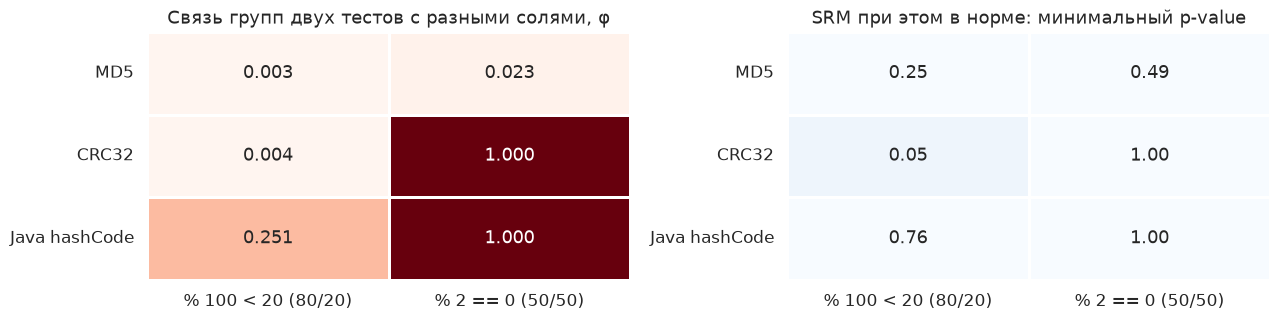

φ: {'MD5': {'% 100 < 20 (80/20)': 0.003, '% 2 == 0 (50/50)': 0.023}, 'CRC32': {'% 100 < 20 (80/20)': 0.004, '% 2 == 0 (50/50)': 1.0}, 'Java hashCode': {'% 100 < 20 (80/20)': 0.251, '% 2 == 0 (50/50)': 1.0}}
SRM min p: {'MD5': {'% 100 < 20 (80/20)': 0.25, '% 2 == 0 (50/50)': 0.49}, 'CRC32': {'% 100 < 20 (80/20)': 0.05, '% 2 == 0 (50/50)': 1.0}, 'Java hashCode': {'% 100 < 20 (80/20)': 0.76, '% 2 == 0 (50/50)': 1.0}}


In [3]:
ids = np.arange(1_000_000, 1_020_000)
HASHES = {'MD5': md5_hash, 'CRC32': crc32_hash, 'Java hashCode': java_hash}
RULES = {'% 2 == 0 (50/50)': lambda v: v % 2 == 0, '% 100 < 20 (80/20)': lambda v: v % 100 < 20}
SALT_PAIRS = [(f'exp_{k}a', f'exp_{k}b') for k in range(3)]


def phi(a: np.ndarray, b: np.ndarray) -> float:
    return abs(np.corrcoef(a, b)[0, 1])


phi_table, srm_table = {}, {}
for hash_name, fn in HASHES.items():
    hashed = [(fn(ids, s1), fn(ids, s2)) for s1, s2 in SALT_PAIRS]
    for rule_name, rule in RULES.items():
        share = 0.5 if '50' in rule_name else 0.2
        phi_table[(hash_name, rule_name)] = max(phi(rule(h1), rule(h2)) for h1, h2 in hashed)
        srm_table[(hash_name, rule_name)] = min(srm_test([(~rule(h1)).sum(), rule(h1).sum()], [1 - share, share]) for h1, _ in hashed)

phi_map = pd.Series(phi_table).unstack().reindex(list(HASHES))
srm_map = pd.Series(srm_table).unstack().reindex(list(HASHES))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
sns.heatmap(phi_map, annot=True, fmt='.3f', cmap='Reds', vmin=0, vmax=1, cbar=False, linewidths=1, ax=axes[0])
axes[0].set_title('Связь групп двух тестов с разными солями, φ')
sns.heatmap(srm_map, annot=True, fmt='.2f', cmap='Blues_r', vmin=0, vmax=0.05, cbar=False, linewidths=1, ax=axes[1])
axes[1].set_title('SRM при этом в норме: минимальный p-value')
for ax in axes:
    ax.set_ylabel('')
    ax.set_xlabel('')
plt.tight_layout()
plt.show()
print('φ:', phi_map.round(3).to_dict('index'))
print('SRM min p:', srm_map.round(2).to_dict('index'))

In [4]:
base = np.arange(1_000_000, 1_050_000)
layer = md5_hash(base, 'layer-1') % 2 == 0                       # слой делит трафик: exp_1 / exp_2
same = layer                                                      # внутри — та же соль слоя
own_1, own_2 = md5_hash(base, 'exp_1') % 2 == 0, md5_hash(base, 'exp_2') % 2 == 0
print(f"Одна соль на слой и вариант: доля B в exp_1 = {same[layer].mean():.2f}, в exp_2 = {same[~layer].mean():.2f}")
print(f"Двойной посол:               доля B в exp_1 = {own_1[layer].mean():.2f}, в exp_2 = {own_2[~layer].mean():.2f}")
h = md5_hash(base, 'exp_1') % 10_000
prev_b, new_b = h < 5000, h < 2000                  # прошлый 50/50, новый 80/20, соль та же
fresh = md5_hash(base, 'exp_3') % 10_000 < 2000     # новый тест 80/20 со своей солью
print(f"Повтор соли при другом сплите: в B нового теста бывших B прошлого = {prev_b[new_b].mean():.0%}; "
      f"со своей солью = {prev_b[fresh].mean():.0%} (при независимости 50%)")

Одна соль на слой и вариант: доля B в exp_1 = 1.00, в exp_2 = 0.00
Двойной посол:               доля B в exp_1 = 0.50, в exp_2 = 0.50


Повтор соли при другом сплите: в B нового теста бывших B прошлого = 100%; со своей солью = 50% (при независимости 50%)


* **MD5** даёт независимые группы при любом правиле: $\varphi \le 0.023$ — максимум по шести парам. Шум $\varphi \approx 1/\sqrt{n}$ ≈ 0.007, и максимум из шести около 3σ — норма.
* **CRC32 и Java `hashCode` при `% 2`** — $\varphi = 1$: соль не работает, два «разных» теста идут на одних и тех же людях.
* **При `% 100 < 20`** CRC32 становится чистым, а у Java `hashCode` остаётся связь $\varphi \approx 0.25$.
* **Одна соль на слой и вариант** — все пользователи `exp_1` в B, все `exp_2` в A. С двойным посолом — по 50%.
* **Повтор соли** — даже при другом сплите (50/50 → 80/20) все B нового теста — бывшие B прошлого (100%).
* **SRM ничего из этого не видит:** доли групп идеальны.

## 3. Качество выгрузки чекаута

У лога две проблемы. Есть **полные дубли строк** — событие записалось дважды. И есть **пользователи в обеих группах** — после удаления дублей у них остаются записи и в A, и в B. Чистим так: дубли схлопываем, пользователей из обеих групп исключаем целиком.

In [5]:
n_duplicates = int(raw.duplicated().sum())
dedup = raw.drop_duplicates()
groups_per_user = dedup.groupby('user_id')['group'].nunique()
users_both = groups_per_user[groups_per_user > 1].index
n_users_both = len(users_both)
checkout = dedup[~dedup['user_id'].isin(users_both)].reset_index(drop=True)

mismatch_clean = int((checkout['group'] != checkout['user_id'].map(assign_group)).sum())

print(f'Полных дублей: {n_duplicates}; пользователей в обеих группах: {n_users_both}')
print(f'Строк: {spaced(len(raw))} → {spaced(len(checkout))}; группа ≠ хеш: до {mismatch_raw}, после {mismatch_clean}')

Полных дублей: 250; пользователей в обеих группах: 60
Строк: 105 330 → 104 960; группа ≠ хеш: до 60, после 0


**Вопрос.** Почему дубли просто схлопываем, а пользователей из обеих групп исключаем целиком, а не оставляем запись, совпадающую с хешем? Когда такое исключение опасно?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

**Дубль** — одна и та же строка дважды: информации в ней нет, `drop_duplicates()` ничего не теряет. Если не схлопнуть, 250 пользователей посчитаются дважды, а SE занизится — n завышен.

**Пользователь в обеих группах** — мы не знаем, что он видел: старый чекаут, новый или оба. Его метрики относятся к смеси вариантов. Запись «по хешу» оставлять нельзя: мы знаем, куда его *назначили*, но не что ему *показали*. Поэтому исключаем целиком.

Опасно, когда таких много или они перекошены по группам. Если баг бьёт только по B (скажем, по одной версии приложения), исключение меняет состав B, и рандомизация ломается. Поэтому после любой очистки — снова SRM. У нас 60 пользователей — 0.06%, на результат это не влияет, но причину (рассинхрон логирования с назначением) надо передать платформе.

**А если строго по ITT?** Тогда пользователя оставляют в группе назначения (по хешу) с его метриками. Это честно по отношению к рандомизации, но разбавляет эффект смешанными пользователями. При 0.06% разница стратегий пренебрежимо мала; при заметной доле считайте обе и пишите об этом в отчёте.

</details>

## 4. SRM: доли групп против плана

**SRM** (sample ratio mismatch) — фактический сплит не совпадает с плановым. Проверяем критерием согласия $\chi^2$ против *заданного* сплита 80/20, а не против 50/50 и не тестом «A против B»:

$$
\chi^2 = \sum_{g} \frac{(n_g - N s_g)^2}{N s_g}
$$

Здесь сумма по группам A и B, $N$ — всего пользователей, $s_A = 0.8$ и $s_B = 0.2$ — плановые доли, одна степень свободы.

Порог строгий — $p < 0.001$ на каждую проверку (весь тест, день, срез), без поправок. Проверок много, и ложная тревога дорога. Но SRM, найденный при этом пороге, «на случайность» не списывают: эффект не считаем, пока не найдена причина.

In [6]:
raw_counts = raw['group'].value_counts().reindex(['A', 'B'])
group_counts = checkout['group'].value_counts().reindex(['A', 'B'], fill_value=0)
srm_p = srm_test(group_counts, [0.8, 0.2])
print(f"Сырой лог (строки):  A {spaced(raw_counts['A'])}, B {spaced(raw_counts['B'])}, доля B = {raw_counts['B'] / raw_counts.sum():.4f}, "
      f"SRM p = {srm_test(raw_counts, [0.8, 0.2]):.2f}")
print(f"После очистки:       A {spaced(group_counts['A'])}, B {spaced(group_counts['B'])}, доля B = {group_counts['B'] / group_counts.sum():.4f}, "
      f"SRM p = {srm_p:.3f}")
p_wrong = srm_test(group_counts, [0.5, 0.5])
print(f"Ошибка: χ² против 50/50 даёт {'p = ' + format(p_wrong, '.1e') if p_wrong > 0 else 'p < 1e-300'} — «SRM» на ровном месте")

daily = checkout.groupby('date')['group'].agg(
    n='size',
    share_b=lambda g: (g == 'B').mean(),
    p_value=lambda g: srm_test([(g == 'A').sum(), (g == 'B').sum()], [0.8, 0.2]),
)
daily.round(4)

Сырой лог (строки):  A 84 141, B 21 189, доля B = 0.2012, SRM p = 0.34
После очистки:       A 83 878, B 21 082, доля B = 0.2009, SRM p = 0.487
Ошибка: χ² против 50/50 даёт p < 1e-300 — «SRM» на ровном месте


,n,share_b,p_value
date,,,
2026-09-07,7406,0.2047,0.3120
2026-09-08,7545,0.1963,0.4203
2026-09-09,7541,0.1975,0.5804
2026-09-10,7505,0.1987,0.7729
2026-09-11,7402,0.1959,0.3770
2026-09-12,7500,0.1995,0.9081
2026-09-13,7577,0.2014,0.7608
2026-09-14,7531,0.1969,0.5039
2026-09-15,7490,0.2049,0.2852


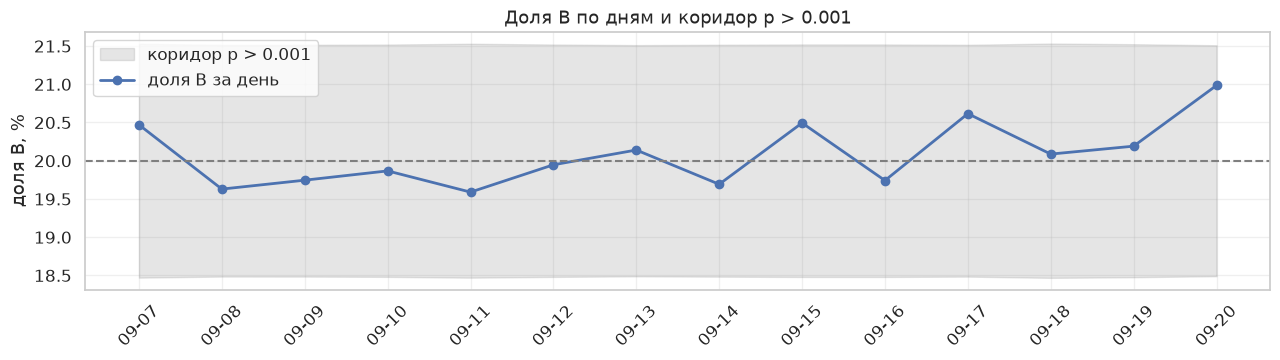

In [7]:
fig, ax = plt.subplots(figsize=(13, 3.8))
se = np.sqrt(0.2 * 0.8 / daily['n'])
ax.fill_between(range(len(daily)), (0.2 - 3.29 * se) * 100, (0.2 + 3.29 * se) * 100, color=GRAY, alpha=0.2, label='коридор p > 0.001')
ax.plot(range(len(daily)), daily['share_b'] * 100, 'o-', color=BLUE, linewidth=2, label='доля B за день')
ax.axhline(20, color=GRAY, linestyle='--')
ax.set_xticks(range(len(daily)))
ax.set_xticklabels([d[5:] for d in daily.index], rotation=45)
ax.set_ylabel('доля B, %')
ax.set_title('Доля B по дням и коридор p > 0.001')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

**Вопрос.** В последний день $p = 0.032$. Это SRM? Что сказать, если владелец продукта увидит этот день на дашборде?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Нет. Порог SRM — 0.001 на **каждую** проверку, без поправок, и 0.032 до него далеко. Этот порог уже рассчитан на много проверок: 14 дневных проверок при исправном сплите дают хотя бы одну ложную тревогу с вероятностью не больше 14 × 0.001 = 1.4%. При пороге 0.05 было бы $1 - 0.95^{14} \approx 0.51$, то есть каждый второй исправный тест с «тревогой». Доля B в этот день — 21.0% при коридоре ±3.29σ ≈ ±1.5 п.п.

Ответ владельцу: «Сплит в норме и в целом ($p = 0.49$), и в каждый день. Мелкие колебания доли по дням — шум». Если бы день вышел за коридор, смотрели бы, что в этот день случилось: релиз, акция, сбой логирования.

</details>

## 5. A/A по солям и мощность SRM

SRM проверяет доли групп. **Множественные A/A** проверяют сам механизм сплита: прогоняем сотни A/A на исторических данных с разными солями. Если сплит случаен, p-value равномерны на отрезке от 0 до 1 и значимы около 5%.

**Вопрос.** На тех же пользователях до нас шёл тест `checkout-v1`, и у его варианта остался небольшой эффект (+0.15σ). Платформа делит трафик Java `hashCode` с правилом `% 100 < 20`. Что покажут 200 A/A с разными солями? Что, кроме доли значимых, стоит проверить?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

**Значимых A/A — 26% вместо 5%**, каждый четвёртый A/A «находит» эффект. Группы A/A связаны с группами прошлого теста (та самая связь $\varphi \approx 0.25$ из раздела 2), и остаточный эффект `checkout-v1` выглядит как эффект A/A. У MD5 в том же сценарии — 3%, в пределах шума для 200 солей.

**Второй признак — доля B слишком стабильна:** её разброс по солям 0.0013 при биномиальном 0.0063, в 5 раз меньше. Случайный сплит так ровно не делит. Слишком ровные группы — такой же сигнал поломки, как перекошенные.

</details>

Прогоняем 200 A/A с солями `aa_0 … aa_199` на 4 тыс. последовательных `user_id` для MD5 и Java `hashCode`.

MD5            доля p < 0.05: 3.0%; разброс доли B: 0.0071 (ожидается 0.0063)


Java hashCode  доля p < 0.05: 26.0%; разброс доли B: 0.0013 (ожидается 0.0063)


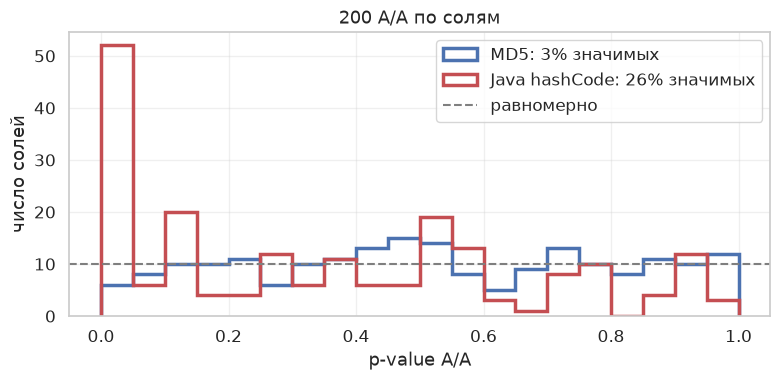

In [8]:
rng = np.random.default_rng(3)
aa_ids = np.arange(1_000_000, 1_004_000)
noise = rng.normal(0, 1, aa_ids.size)

aa = {}
for name, fn in {'MD5': md5_hash, 'Java hashCode': java_hash}.items():
    previous_b = fn(aa_ids, 'checkout-v1') % 100 < 20
    metric = noise + 0.15 * previous_b                       # остаточный эффект прошлого теста
    pvalues, shares = [], []
    for k in range(200):
        b = fn(aa_ids, f'aa_{k}') % 100 < 20
        pvalues.append(stats.ttest_ind(metric[b], metric[~b], equal_var=False).pvalue)
        shares.append(b.mean())
    aa[name] = (np.array(pvalues), np.array(shares))
    print(f"{name:14s} доля p < 0.05: {np.mean(aa[name][0] < 0.05):.1%}; "
          f"разброс доли B: {np.std(shares):.4f} (ожидается {np.sqrt(0.16 / aa_ids.size):.4f})")

fig, ax = plt.subplots(figsize=(8, 4))
for (name, (pvalues, _)), color in zip(aa.items(), [BLUE, RED]):
    ax.hist(pvalues, bins=20, range=(0, 1), histtype='step', linewidth=2.5, color=color,
            label=f'{name}: {np.mean(pvalues < 0.05):.0%} значимых')
ax.axhline(200 / 20, color=GRAY, linestyle='--', label='равномерно')
ax.set_xlabel('p-value A/A')
ax.set_ylabel('число солей')
ax.set_title('200 A/A по солям')
ax.legend()
plt.tight_layout()
plt.show()

Та же проверка на исправной схеме и реальных данных: 20 тыс. пользователей группы A чекаута (эффекта у них нет), 100 A/A с солями `aa_0 … aa_99` и сплитом 80/20 через `assign_group`.

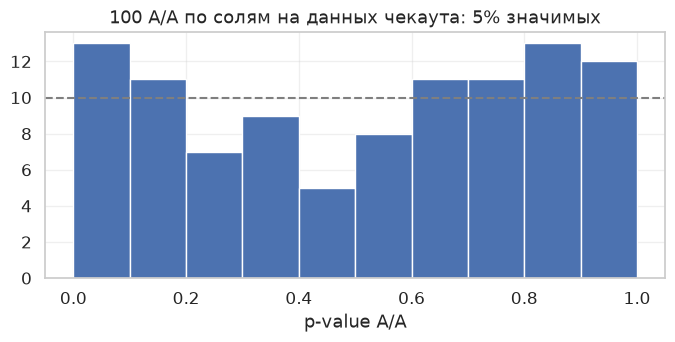

Доля p < 0.05: 5%; тест Колмогорова — Смирнова на равномерность: p = 0.30


In [9]:
aa_users = checkout[checkout['group'] == 'A'].sample(20_000, random_state=1)
aa_pvalues = []
for k in range(100):
    b = aa_users['user_id'].map(lambda u: assign_group(u, salt=f'aa_{k}') == 'B').to_numpy()
    y = aa_users['converted'].to_numpy()
    delta = y[b].mean() - y[~b].mean()
    se = np.sqrt(y[b].var() / b.sum() + y[~b].var() / (~b).sum())
    aa_pvalues.append(2 * stats.norm.sf(abs(delta / se)))
aa_pvalues = np.array(aa_pvalues)
aa_fpr = (aa_pvalues < 0.05).mean()

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(aa_pvalues, bins=10, range=(0, 1), color=BLUE)
ax.axhline(10, color=GRAY, linestyle='--')
ax.set_xlabel('p-value A/A')
ax.set_title(f'100 A/A по солям на данных чекаута: {aa_fpr:.0%} значимых')
plt.show()
print(f'Доля p < 0.05: {aa_fpr:.0%}; тест Колмогорова — Смирнова на равномерность: p = {stats.kstest(aa_pvalues, "uniform").pvalue:.2f}')

Исправный сплит: значимых около 5%, гистограмма ровная. Теперь вторая сторона SRM — насколько он чувствителен.

**Вопрос.** SRM-проверка на всём тесте дала $p < 0.001$. Может, просто не повезло?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Почти наверняка нет. Ложная тревога при исправном сплите — 0.1%, поэтому «не повезло» — почти никогда не объяснение.

Мощность — отдельный вопрос: проверка ловит даже небольшую потерю. На всём тесте чекаута (105 тыс.) она с вероятностью 80% замечает потерю всего 3.2% пользователей B, на двух днях (15 тыс.) — 8.3%. Значит, и мелкая неслучайная поломка даст SRM. А неслучайная потеря нескольких процентов пользователей легко создаёт «эффект» того же размера, что мы ищем (раздел 7).

</details>

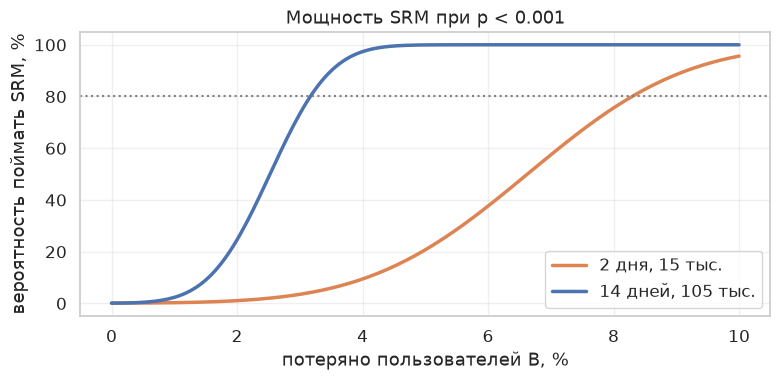

n = 15 000: 80% мощности при потере 8.3% пользователей B
n = 105 000: 80% мощности при потере 3.2% пользователей B


In [10]:
def srm_power(lost: np.ndarray, n: int, share: float = 0.2, alpha: float = 0.001) -> np.ndarray:
    """Вероятность поймать SRM, если теряется доля lost пользователей B."""
    observed = share * (1 - lost) / (1 - share * lost)
    se = np.sqrt(share * (1 - share) / n)
    z = stats.norm.isf(alpha / 2)
    shift = (observed - share) / se
    return stats.norm.cdf(-z - shift) + stats.norm.sf(z - shift)


lost = np.linspace(0, 0.10, 201)
fig, ax = plt.subplots(figsize=(8, 4))
for n, color, label in [(15_000, ORANGE, '2 дня, 15 тыс.'), (105_000, BLUE, '14 дней, 105 тыс.')]:
    ax.plot(lost * 100, srm_power(lost, n) * 100, color=color, linewidth=2.5, label=label)
ax.axhline(80, color=GRAY, linestyle=':')
ax.set_xlabel('потеряно пользователей B, %')
ax.set_ylabel('вероятность поймать SRM, %')
ax.set_title('Мощность SRM при p < 0.001')
ax.legend()
plt.tight_layout()
plt.show()
for n in [15_000, 105_000]:
    print(f"n = {n:,}: 80% мощности при потере {lost[np.argmax(srm_power(lost, n) >= 0.8)]:.1%} пользователей B".replace(',', ' '))

## 6. SRM-детектив: пять выгрузок — пять причин

SRM найден — значит, ищем причину. Типовых причин пять, и у каждой свой след в данных:

| Причина | Механизм | Признак в данных |
| --- | --- | --- |
| Баг назначения | SDK при ошибке кладёт пользователя в контроль; разные реализации хеша | Дефицит B в одном устройстве / версии; A больше плана; группа ≠ пересчитанный хеш |
| Ботфильтр / антифрод после назначения | Фильтр срабатывает по поведению, а вариант меняет поведение | Со всеми строками сплит честный, после фильтра — нет; доля ботов разная по группам |
| Потери телеметрии в одной группе | Вариант шлёт события иначе (пачкой, позже, другой библиотекой) | Дефицит равномерный по срезам; другое распределение задержки события; обрыв на окне пайплайна |
| Триггер / редирект только в одной ветке | В B лишний переход или другое условие логирования | Дефицит в одном источнике (реклама, диплинки); сдвиг минимальной задержки в B (виден в нижнем хвосте, не в медиане) |
| Неверная дата старта / кэш | Вариант включился позже, CDN отдавал старую страницу | Дефицит B только в первые дни, дальше — по плану |

Платформа прислала пять тестов с тревогой SRM (`../data/srm_case_{1..5}.csv`), по одному на причину. Все — сплит 80/20, 14 дней. Колонки: `device` (ios / android / web), `source` (organic / ads / push / email), `is_bot` (антифрод пометил ботом), `lag_sec` (секунд от назначения до первого события теста в логе). Платформа считает тест по строкам с `is_bot == 0`.

Порядок осмотра каждого кейса: SRM без ботов и со всеми строками → доля ботов по группам → доля B по устройствам, источникам и дням → квантили `lag_sec` по группам. Срез, где доля B проседает сильнее всего, и есть подсказка.

In [11]:
cases = {k: pd.read_csv(DATA / f'srm_case_{k}.csv') for k in range(1, 6)}
for k, df in cases.items():
    humans = df[df['is_bot'] == 0]
    print(f"Кейс {k}: {spaced(len(df))} строк, доля B без ботов = {(humans['group'] == 'B').mean():.4f}")
cases[1].head()

Кейс 1: 29 901 строк, доля B без ботов = 0.1758
Кейс 2: 30 926 строк, доля B без ботов = 0.1826
Кейс 3: 30 975 строк, доля B без ботов = 0.1898
Кейс 4: 30 855 строк, доля B без ботов = 0.1610
Кейс 5: 30 412 строк, доля B без ботов = 0.1895


,user_id,date,group,device,source,is_bot,lag_sec,converted
0,94127475,2026-09-07,A,ios,organic,0,17.2,1
1,91536574,2026-09-07,A,android,email,0,16.7,0
2,28168014,2026-09-07,A,ios,push,0,29.6,0
3,50974619,2026-09-09,A,ios,ads,0,15.7,0
4,70288271,2026-09-16,A,web,ads,0,11.1,0


In [12]:
def srm_by(df: pd.DataFrame, col: str) -> pd.DataFrame:
    return df.groupby(col)['group'].agg(
        n='size',
        share_b=lambda g: (g == 'B').mean(),
        p_value=lambda g: srm_test([(g == 'A').sum(), (g == 'B').sum()], [0.8, 0.2]),
    )


def investigate(k: int) -> None:
    df = cases[k]
    humans = df[df['is_bot'] == 0]
    print(f"===== Кейс {k}: SRM без ботов p = {srm_test(humans['group'].value_counts().reindex(['A', 'B']), [0.8, 0.2]):.1e}, "
          f"со всеми строками p = {srm_test(df['group'].value_counts().reindex(['A', 'B']), [0.8, 0.2]):.1e}")
    print('доля ботов по группам:', df.groupby('group')['is_bot'].mean().round(3).to_dict())
    for col in ['device', 'source']:
        print(srm_by(humans, col).round(4).T.to_string(), '\n')
    print('доля B по дням:', srm_by(humans, 'date')['share_b'].round(3).tolist())
    print('lag_sec по группам (квантили 1%, 50%, 99%):')
    print(humans.groupby('group')['lag_sec'].quantile([0.01, 0.5, 0.99]).unstack().round(1).to_string(), '\n')


for k in cases:
    investigate(k)

===== Кейс 1: SRM без ботов p = 5.4e-25, со всеми строками p = 5.0e-28
доля ботов по группам: {'A': 0.031, 'B': 0.023}
device      android         ios        web
n        11684.0000  10246.0000  7088.0000
share_b      0.1757      0.1746     0.1775
p_value      0.0000      0.0000     0.0000 

source         ads      email     organic       push
n        7980.0000  4505.0000  11971.0000  4562.0000
share_b     0.1229     0.1905      0.1982     0.1947
p_value     0.0000     0.1092      0.6281     0.3665 



доля B по дням: [0.183, 0.174, 0.174, 0.176, 0.171, 0.17, 0.172, 0.173, 0.177, 0.181, 0.164, 0.195, 0.171, 0.18]
lag_sec по группам (квантили 1%, 50%, 99%):
       0.01  0.50   0.99
group                   
A       2.4  25.2  262.7
B       3.9  25.8  253.4 

===== Кейс 2: SRM без ботов p = 5.1e-14, со всеми строками p = 7.3e-15


доля ботов по группам: {'A': 0.03, 'B': 0.027}
device      android         ios        web
n        12175.0000  10486.0000  7363.0000
share_b      0.1791      0.1862     0.1832
p_value      0.0000      0.0004     0.0003 



source         ads      email     organic       push
n        8666.0000  4573.0000  12151.0000  4634.0000
share_b     0.1837     0.1703      0.1871     0.1811
p_value     0.0001     0.0000      0.0004     0.0013 



доля B по дням: [0.047, 0.126, 0.206, 0.184, 0.212, 0.202, 0.198, 0.193, 0.197, 0.197, 0.201, 0.201, 0.195, 0.193]
lag_sec по группам (квантили 1%, 50%, 99%):
       0.01  0.50   0.99
group                   
A       2.4  24.7  266.2
B       2.3  24.7  284.4 

===== Кейс 3: SRM без ботов p = 1.0e-05, со всеми строками p = 9.2e-01
доля ботов по группам: {'A': 0.03, 'B': 0.093}


device      android         ios        web
n        11925.0000  10481.0000  7243.0000
share_b      0.1931      0.1869     0.1883
p_value      0.0605      0.0008     0.0129 



... (2 outputs left out)

device      android         ios        web
n        12057.0000  10514.0000  7300.0000
share_b      0.1992      0.0916     0.1978
p_value      0.8305      0.0000     0.6397 

source        ads      email     organic       push
n        8746.000  4499.0000  12027.0000  4599.0000
share_b     0.162     0.1618      0.1611     0.1579
p_value     0.000     0.0000      0.0000     0.0000 



доля B по дням: [0.165, 0.152, 0.166, 0.16, 0.171, 0.164, 0.155, 0.152, 0.165, 0.162, 0.156, 0.158, 0.171, 0.157]
lag_sec по группам (квантили 1%, 50%, 99%):
       0.01  0.50   0.99
group                   
A       2.5  25.0  253.3
B       2.4  25.1  269.0 

===== Кейс 5: SRM без ботов p = 6.3e-06, со всеми строками p = 6.6e-06
доля ботов по группам:

 {'A': 0.03, 'B': 0.032}
device      android         ios        web
n        11949.0000  10376.0000  7156.0000
share_b      0.1883      0.1936     0.1854
p_value      0.0014      0.1042     0.0021 



source         ads      email     organic       push
n        8556.0000  4461.0000  11963.0000  4501.0000
share_b     0.1918     0.1910      0.1898     0.1828
p_value     0.0578     0.1324      0.0051     0.0040 

доля B по дням: [0.19, 0.183, 0.18, 0.189, 0.197, 0.192, 0.19, 0.192, 0.184, 0.192, 0.186, 0.195, 0.199, 0.183]
lag_sec по группам (квантили 1%, 50%, 99%):
       0.01   0.50    0.99
group                     
A       2.4   24.7   269.9
B      37.0  897.4  3446.4 



**Вопрос.** По срезам и графикам выше назовите причину SRM в каждом из пяти кейсов. Можно ли хоть один из этих тестов спасти?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

| Кейс | Причина | Признак | Что делать |
| :---: | --- | --- | --- |
| 1 | Редирект только в B | Дефицит B только в `source = ads` (12% вместо 20%); нижний хвост `lag_sec` у B сдвинут (1-й перцентиль 3.9 против 2.4 с) — лишний переход; по медиане сдвиг тонет в шуме | Рендерить вариант на том же URL или логировать назначение до редиректа |
| 2 | Дата старта / кэш | Доля B ~5% в первый день, ~13% во второй, дальше 20%; по устройствам и источникам дефицит равномерный | Считать с фактического включения (с третьего дня); при старте сбрасывать кэш |
| 3 | Ботфильтр после назначения | Со всеми строками сплит честный (p = 0.92); ботов 3% в A и 9% в B | Фильтровать ботов по признакам до назначения, проверять SRM до и после фильтра |
| 4 | Баг назначения | На iOS доля B 9%, на android и web — 20%; iOS-пользователей столько же, сколько в других кейсах, — B не потеряны, а переложены в A | Чинить SDK: при ошибке исключать из теста, а не класть в контроль |
| 5 | Потери телеметрии | У B задержка событий — минуты, обрыв ровно на 3600 с; дефицит равномерный по срезам | Слать событие с сервера; окно пайплайна больше максимального лага |

Общий приём: сначала все строки без фильтров, затем срезы по времени, по сегментам, по задержке. Срез, где сидит дисбаланс, почти всегда называет причину.

Спасти можно только тест, где есть честная подвыборка: кейс 2 с третьего дня, после повторной проверки SRM на этом периоде. Остальные четыре не анализируем, пока причина не устранена. В генераторе данных `../data/generate_srm_cases.py` ответы лежат в словаре `ANSWERS`.

</details>

Графики к ответу: ключевой срез каждого кейса.

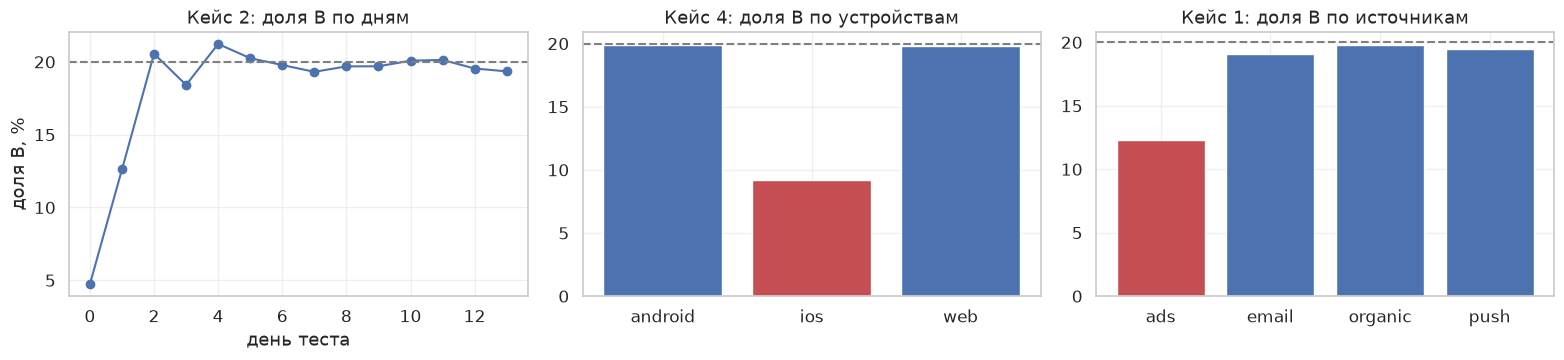

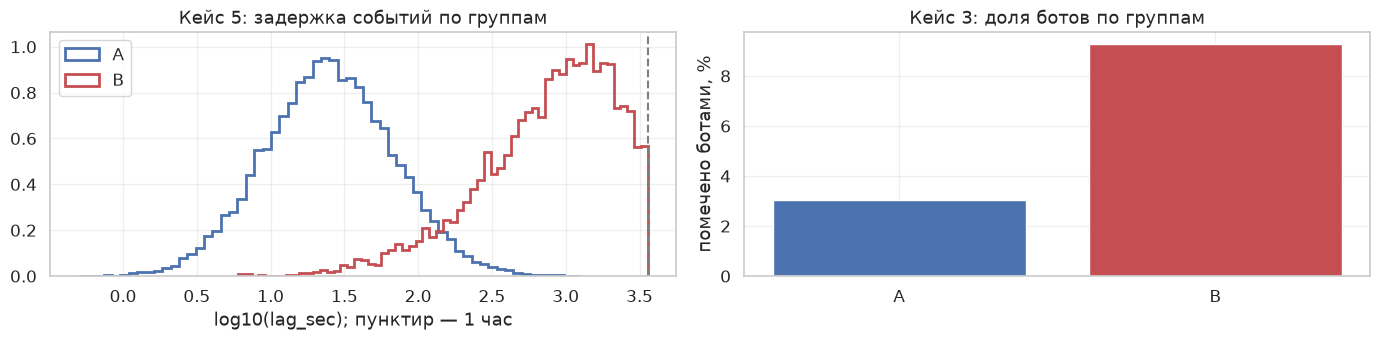

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
day_share = srm_by(cases[2][cases[2]['is_bot'] == 0], 'date')['share_b']
axes[0].plot(range(len(day_share)), day_share * 100, 'o-', color=BLUE)
axes[0].axhline(20, color=GRAY, linestyle='--')
axes[0].set_title('Кейс 2: доля B по дням')
axes[0].set_xlabel('день теста')
axes[0].set_ylabel('доля B, %')
for k, ax, col, title in [(4, axes[1], 'device', 'Кейс 4: доля B по устройствам'), (1, axes[2], 'source', 'Кейс 1: доля B по источникам')]:
    share = srm_by(cases[k][cases[k]['is_bot'] == 0], col)['share_b']
    ax.bar(share.index, share * 100, color=[RED if v < 0.17 else BLUE for v in share])
    ax.axhline(20, color=GRAY, linestyle='--')
    ax.set_title(title)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
humans = cases[5][cases[5]['is_bot'] == 0]
for group, color in [('A', BLUE), ('B', RED)]:
    axes[0].hist(np.log10(humans.loc[humans['group'] == group, 'lag_sec']), bins=60, density=True, histtype='step', linewidth=2, color=color, label=group)
axes[0].axvline(np.log10(3600), color=GRAY, linestyle='--')
axes[0].set_xlabel('log10(lag_sec); пунктир — 1 час')
axes[0].set_title('Кейс 5: задержка событий по группам')
axes[0].legend()
bots = cases[3].groupby('group')['is_bot'].mean() * 100
axes[1].bar(bots.index, bots, color=[BLUE, RED])
axes[1].set_ylabel('помечено ботами, %')
axes[1].set_title('Кейс 3: доля ботов по группам')
plt.tight_layout()
plt.show()

## 7. Как SRM смещает эффект

Почему при SRM нельзя «просто посчитать эффект с оговоркой»? Возьмём кейс 4. Баг назначения на iOS перекладывает пользователей B в A, а эффекта у варианта нет по построению.

**Вопрос.** В кейсе 4 эффекта у варианта нет по построению. Что покажет разница конверсий B − A «в лоб» и почему? Спасает ли разбивка по устройствам?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

«В лоб» получится заметное ухудшение: −2.8 п.п. Причина — состав групп: iOS конвертируются в 39% против 29–30% у остальных, а в B их стало вдвое меньше. Средняя конверсия B падает просто за счёт состава, без всякого эффекта варианта.

Стратифицированная оценка — разницы внутри устройств, взвешенные долями устройств — даёт −1.0 п.п. и лежит в пределах шума (SE ≈ 0.8 п.п.).

Но и она спасает только тогда, когда поломка целиком сидит в известном срезе. Внутри iOS в B остались не случайные пользователи, а те, у кого SDK не сломался. При SRM сравнение групп — это сравнение разных популяций, и такой тест уже не рандомизированный.

</details>

In [14]:
case4 = cases[4][cases[4]['is_bot'] == 0]


def conv_diff(df: pd.DataFrame) -> float:
    return (df.loc[df['group'] == 'B', 'converted'].mean() - df.loc[df['group'] == 'A', 'converted'].mean()) * 100


naive_effect = conv_diff(case4)
by_device = case4.groupby('device').apply(conv_diff, include_groups=False)
weights = case4['device'].value_counts(normalize=True)
stratified = float((by_device * weights).sum())


def conv_diff_se(df: pd.DataFrame) -> float:
    a, b = df.loc[df['group'] == 'A', 'converted'], df.loc[df['group'] == 'B', 'converted']
    return np.sqrt(a.var() / len(a) + b.var() / len(b)) * 100


se_dev = case4.groupby('device').apply(conv_diff_se, include_groups=False)
se_naive = conv_diff_se(case4)
se_strat = float(np.sqrt(((weights * se_dev) ** 2).sum()))
print(case4.groupby('device')['converted'].mean().round(3).to_dict())
print(f'В лоб: {naive_effect:+.2f} п.п. (SE {se_naive:.2f}); стратифицированно: {stratified:+.2f} п.п. (SE {se_strat:.2f})')
print(pd.DataFrame({'разница, п.п.': by_device, 'SE, п.п.': se_dev}).round(2).to_string())

{'android': 0.295, 'ios': 0.391, 'web': 0.291}
В лоб: -2.76 п.п. (SE 0.73); стратифицированно: -0.97 п.п. (SE 0.78)
         разница, п.п.  SE, п.п.
device                          
android          -1.21      1.03
ios              -0.73      1.65
web              -0.95      1.33


## 8. Телеметрия и триггеринг

Изменение часто затрагивает часть пользователей. Баннер рассрочки показывают только при корзине дороже 5 000 ₽ — это 40% пользователей. Есть три способа посчитать эффект:

* **ITT** — по всем назначенным. Честно, но эффект разбавлен: 60% пользователей баннер не видят и добавляют только шум.
* **По триггеру** — только затронутые, причём триггер определён *одинаково в обеих группах и до воздействия*: серверный флаг «корзина дороже 5 000 ₽», а в контроле логируем «показали бы».
* **По клиентскому событию показа** — «кого залогировали как увидевшего баннер».

**Разбавление.** Для аддитивной метрики, если на незатронутых эффекта нет, эффект на всех равен эффекту на затронутых, умноженному на долю затронутых:

$$
\Delta_{ITT} = \Delta_{trigger} \cdot \frac{N_{trigger}}{N}
$$

Симуляция: 56 тыс. назначенных, 50/50, конверсия затронутых 55% → 57% (+2 п.п.), незатронутых — 70%. Клиентское событие показа часть пользователей теряет, в A и B по-разному (параметры — в `trigger_trial`). 300 повторов при эффекте 0 и при +2 п.п.

**Вопрос.** Какой из трёх способов при нулевом эффекте «найдёт» эффект? А какой лучше всех найдёт настоящий?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

**Клиентское событие** ломает всё: при нулевом эффекте даёт в среднем +3.3 п.п. и «значимость» в 99% тестов. Разницу создаёт отбор, а не баннер. В A событие теряется у 2%, в B — у 3% купивших и 15% не купивших: баннер шлёт событие пачкой через несколько секунд, а кто закрыл вкладку раньше, тот обычно и не купил. В B остаются более «успешные» пользователи.

**ITT** честен (около 5% ложных срабатываний), но слаб: эффект разбавлен в 2.5 раза, и находит его лишь 47% тестов.

**Честный триггер** держит уровень и находит эффект в 86% тестов: шум 60% незатронутых ушёл. Перевод на всех — эффект триггера × 0.4 — согласуется с ITT, но его SE в 1.5 раза меньше. В этом выигрыш триггера.

</details>

,,"оценка, п.п.",доля p < 0.05,"SE, п.п."
ITT,0.00,-0.024,0.037,0.406
триггер,0.00,0.031,0.063,0.665
клиентское событие,0.00,3.269,0.990,0.680
ITT,0.02,0.798,0.473,0.405
триггер,0.02,2.014,0.860,0.663
клиентское событие,0.02,5.208,1.000,0.677


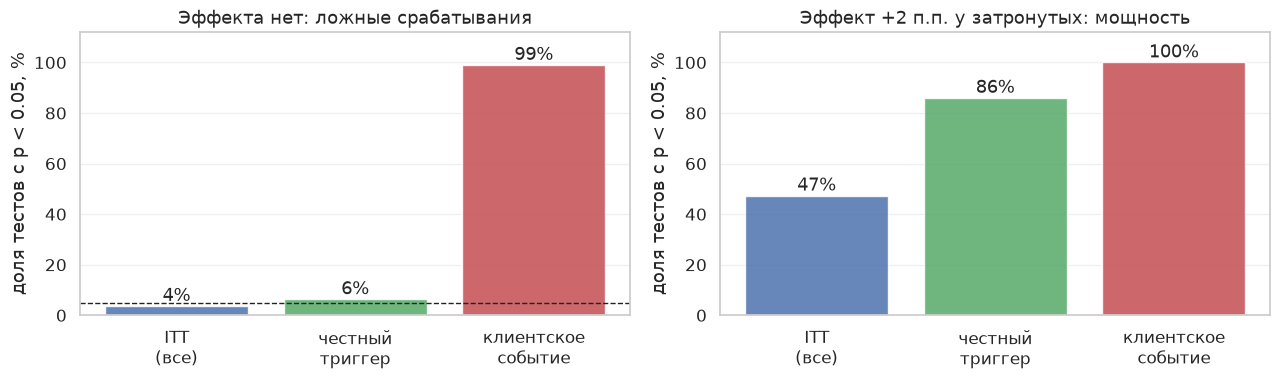

In [15]:
TRIGGER_SHARE, EFFECT = 0.40, 0.02


def trigger_trial(rng, effect, n=28_000):
    """Один тест: ITT, честный триггер и триггер по клиентскому событию. Возвращает (оценка, p-value) для каждого."""
    out = {}
    group = np.r_[np.zeros(n), np.ones(n)].astype(bool)
    triggered = rng.random(2 * n) < TRIGGER_SHARE
    p = np.where(triggered, 0.55 + effect * group, 0.70)
    converted = rng.random(2 * n) < p
    loss = np.where(group, np.where(converted, 0.03, 0.15), 0.02)
    logged = triggered & (rng.random(2 * n) >= loss)
    for name, mask in [('ITT', np.ones(2 * n, bool)), ('триггер', triggered), ('клиентское событие', logged)]:
        a, b = converted[mask & ~group], converted[mask & group]
        delta = b.mean() - a.mean()
        se = np.sqrt(a.var() / a.size + b.var() / b.size)
        out[name] = (delta, 2 * stats.norm.sf(abs(delta / se)), se)
    return out


rng = np.random.default_rng(7)
summary = {}
for effect in [0.0, EFFECT]:
    trials = [trigger_trial(rng, effect) for _ in range(300)]
    for name in trials[0]:
        deltas = np.array([t[name][0] for t in trials])
        pvalues = np.array([t[name][1] for t in trials])
        summary[(name, effect)] = {'оценка, п.п.': deltas.mean() * 100, 'доля p < 0.05': (pvalues < 0.05).mean(),
                                   'SE, п.п.': np.mean([t[name][2] for t in trials]) * 100}
summary = pd.DataFrame(summary).T
display(summary.round(3))

names = ['ITT', 'триггер', 'клиентское событие']
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, effect, title in [(axes[0], 0.0, 'Эффекта нет: ложные срабатывания'), (axes[1], EFFECT, 'Эффект +2 п.п. у затронутых: мощность')]:
    values = [summary.loc[(name, effect), 'доля p < 0.05'] * 100 for name in names]
    ax.bar(['ITT\n(все)', 'честный\nтриггер', 'клиентское\nсобытие'], values, color=[BLUE, GREEN, RED], alpha=0.85)
    for k, value in enumerate(values):
        ax.text(k, value + 2, f'{value:.0f}%', ha='center')
    ax.set_ylim(0, 112)
    ax.set_ylabel('доля тестов с p < 0.05, %')
    ax.set_title(title)
    ax.grid(axis='x', visible=False)
axes[0].axhline(5, color='#222222', linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()

In [16]:
se_itt_sim = summary.loc[('ITT', EFFECT), 'SE, п.п.']
se_trig_sim = summary.loc[('триггер', EFFECT), 'SE, п.п.']
print(f"Разбавление: Δ_ITT ≈ Δ_trigger × {TRIGGER_SHARE} = {EFFECT * 100:.2f} × {TRIGGER_SHARE} = {EFFECT * TRIGGER_SHARE * 100:.2f} п.п. "
      f"(симуляция ITT: {summary.loc[('ITT', EFFECT), 'оценка, п.п.']:.2f})")
print(f"SE прямой ITT: {se_itt_sim:.2f} п.п.; SE разбавленной оценки (SE_trigger × {TRIGGER_SHARE}): {se_trig_sim * TRIGGER_SHARE:.2f} п.п. — "
      f"в {se_itt_sim / (se_trig_sim * TRIGGER_SHARE):.1f} раза уже")

Разбавление: Δ_ITT ≈ Δ_trigger × 0.4 = 2.00 × 0.4 = 0.80 п.п. (симуляция ITT: 0.80)
SE прямой ITT: 0.40 п.п.; SE разбавленной оценки (SE_trigger × 0.4): 0.27 п.п. — в 1.5 раза уже


## 9. Тест виджета доставки

Тест нового виджета выбора слота доставки, сплит 50/50, 7 дней, `../data/telemetry_ab.csv`. Виджет видят только пользователи с курьерской доставкой в корзине. Колонки:

* `triggered` — серверный флаг «должен увидеть виджет», одинаковый в обеих группах;
* `exposure_logged` — клиентское событие показа (в A — «показали бы»), часть событий теряется;
* `converted` — заказ по серверу, без потерь.

Считаем потерю событий среди затронутых по группам и устройствам и эффект (разница конверсий B − A в п.п.) тремя способами.

In [17]:
tele = pd.read_csv(DATA / 'telemetry_ab.csv')
tele.groupby('group')[['triggered', 'exposure_logged', 'converted']].mean().round(4)

,triggered,exposure_logged,converted
group,,,
A,0.2496,0.2454,0.3236
B,0.2508,0.2252,0.3311


In [18]:
def effect_pp(df: pd.DataFrame) -> tuple:
    """Разница конверсий B − A в п.п., её SE и p-value z-теста."""
    a, b = df.loc[df['group'] == 'A', 'converted'], df.loc[df['group'] == 'B', 'converted']
    delta = b.mean() - a.mean()
    se = np.sqrt(a.var() / len(a) + b.var() / len(b))
    return delta * 100, se * 100, 2 * stats.norm.sf(abs(delta / se))


triggered_users = tele[tele['triggered'] == 1]
loss = 1 - triggered_users.groupby('group')['exposure_logged'].mean()
itt, se_itt, p_itt = effect_pp(tele)
trig, se_trig, p_trig = effect_pp(triggered_users)
client, se_client, p_client = effect_pp(tele[tele['exposure_logged'] == 1])
share_triggered = tele['triggered'].mean()
dilution = 1 / share_triggered

print('Потеря событий среди затронутых:', loss.round(3).to_dict())
print((1 - triggered_users.groupby(['group', 'device'])['exposure_logged'].mean()).unstack().round(3).to_string(), '\n')
for name, (d, s, p) in {'ITT (все назначенные)': (itt, se_itt, p_itt), 'честный триггер': (trig, se_trig, p_trig),
                        'по клиентскому событию': (client, se_client, p_client)}.items():
    print(f'{name:24s} {d:+.2f} п.п. ± {1.96 * s:.2f}  p = {p:.1e}')
print(f'\nДоля затронутых {share_triggered:.3f} → разбавление в {dilution:.1f} раза')
print(f'Триггер × доля = {trig * share_triggered:+.2f} п.п. ± {1.96 * se_trig * share_triggered:.2f} (сравните с ITT {itt:+.2f} ± {1.96 * se_itt:.2f})')
logged_n = tele.loc[tele['exposure_logged'] == 1, 'group'].value_counts().reindex(['A', 'B'])
trig_n = triggered_users['group'].value_counts().reindex(['A', 'B'])
print(f"Показов залогировано A/B: {logged_n['A']} / {logged_n['B']}, SRM p = {srm_test(logged_n, [0.5, 0.5]):.1e}; "
      f"затронутых A/B: {trig_n['A']} / {trig_n['B']}, SRM p = {srm_test(trig_n, [0.5, 0.5]):.2f}")

Потеря событий среди затронутых: {'A': 0.017, 'B': 0.102}
device  android    ios    web
group                        
A         0.018  0.019  0.012
B         0.233  0.023  0.014 

ITT (все назначенные)    +0.75 п.п. ± 0.77  p = 5.7e-02
честный триггер          +3.06 п.п. ± 1.62  p = 2.2e-04
по клиентскому событию   +5.79 п.п. ± 1.68  p = 1.6e-11

Доля затронутых 0.250 → разбавление в 4.0 раза
Триггер × доля = +0.77 п.п. ± 0.41 (сравните с ITT +0.75 ± 0.77)
Показов залогировано A/B: 6932 / 6342, SRM p = 3.0e-07; затронутых A/B: 7051 / 7063, SRM p = 0.92


**Вопрос.** Какой эффект виджета писать в отчёт? Почему оценка по клиентскому событию почти вдвое больше триггерной?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

* **Эффект на затронутых:** честный триггер, +3.1 п.п. (p = 0.0002). Триггер серверный, определён одинаково в обеих группах и до показа виджета.
* **Эффект на всех:** +3.1 × 0.25 ≈ +0.77 п.п. Прямая ITT-оценка (+0.75 п.п., p = 0.057) с ней согласуется, но из-за шума 75% незатронутых не значима. Разбавленная оценка триггера в 1.9 раза точнее прямой ITT.
* **По клиентскому событию (+5.8 п.п.) — смещено.** В B на android теряется 23% событий показа, и теряются они чаще у тех, кто не купил: 34% показов у не купивших и 9% у купивших (в A — около 2% независимо от покупки). Виджет падает — пользователь уходит. В B остаются более «успешные» пользователи, и эффект завышен почти вдвое.

Это **метрический SRM**: залогированных показов в B 6 342 против 6 932 в A, а затронутых поровну (7 063 и 7 051). SRM по залогированным показам против 50/50 даёт $p \approx 3 \cdot 10^{-7}$, по серверному триггеру — p = 0.92.

Кроме метрики, это ещё и **guardrail-сигнал**: виджет падает у четверти android-пользователей. Это баг продукта, его чинят до решения о раскатке.

</details>

Потеря событий показа среди затронутых — по группе, устройству и факту покупки (`converted`):

In [19]:
(1 - triggered_users.groupby(['group', 'device', 'converted'])['exposure_logged'].mean()).unstack().round(3)

converted          0      1
group device               
A     android  0.017  0.019
      ios      0.018  0.021
      web      0.012  0.012
B     android  0.337  0.087
      ios      0.020  0.026
      web      0.014  0.014

## 10. Guardrail на старте

Первые 1–2 дня смотрим не на эффект, а на поломки: SRM, потери событий, ошибки оплаты, падения, латентность. Порог строгий ($p < 0.001$), действие — остановить показ, а не «подождать».

**Вопрос.** Через два дня после старта у чекаута около 12 тыс. пользователей в A и 3 тыс. в B, ошибка оплаты в A — 2%. Заметим ли мы, если в B она выросла до 3%? А до 4%? Почему тест односторонний, а порог такой строгий?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Рост до 4% виден почти наверняка (≈100%), до 3% — лишь в 64% случаев. Грубые поломки ловятся за пару дней, тонкие ухудшения — только к концу теста.

Тест односторонний, потому что на старте нас интересует только ухудшение: вариант, который *снижает* ошибки, останавливать незачем. Порог 0.001 — потому что guardrail-метрик несколько и смотрим их часто, а остановка теста дорога. Ложная тревога на каждой проверке обходилась бы слишком дорого.

</details>

In [20]:
# Ошибка оплаты 2% в A. Что видно через 2 дня (n_B ≈ 3 000, n_A ≈ 12 000)?
n_a, n_b, p0 = 12_000, 3_000, 0.02
# Одностороннее: ловим только ухудшение. Порог — p < 0.001 одностороннего z-теста (как в п. 10 чек-листа).
z = stats.norm.isf(0.001)
se0 = np.sqrt(p0 * (1 - p0) * (1 / n_a + 1 / n_b))
for p1 in [0.03, 0.04, 0.06]:
    se1 = np.sqrt(p0 * (1 - p0) / n_a + p1 * (1 - p1) / n_b)
    power = stats.norm.sf((z * se0 - (p1 - p0)) / se1)
    print(f"Ошибка оплаты в B {p1:.0%} против {p0:.0%}: через 2 дня ловим с вероятностью {power:.0%}")

Ошибка оплаты в B 3% против 2%: через 2 дня ловим с вероятностью 64%
Ошибка оплаты в B 4% против 2%: через 2 дня ловим с вероятностью 100%
Ошибка оплаты в B 6% против 2%: через 2 дня ловим с вероятностью 100%


## 11. Чек-лист запуска и данные для встречи 6

Шаблон `launch_checklist.md` в папке встречи — 15 проверок с порогами в трёх разделах: до старта, первые 48 часов и перед анализом. У каждой — способ проверки, порог, действие при провале и пустые колонки «Факт» и «OK / что сделали». Для чекаута у нас есть данные для раздела «Перед анализом» (кроме срезов п. 14 по устройствам, источникам и ботфильтру — в выгрузке нет этих колонок) и для пункта 4 («Группа воспроизводится»).

In [21]:
text = Path('launch_checklist.md').read_text(encoding='utf-8')
print(text[text.index('## Перед анализом'):text.index('## Пять типовых')])

## Перед анализом

| № | Проверка | Как проверяем | Порог | Если не прошли | Факт | OK / что сделали |
| :---: | --- | --- | --- | --- | --- | --- |
| 12 | Полные дубли строк | `df.duplicated().sum()` | любое число → схлопнуть; > 1% строк → разбираться с логированием | `drop_duplicates()` и записать число в отчёт | | |
| 13 | Пользователи в обеих группах | `groupby('user_id').group.nunique() > 1` | < 0.1% пользователей и в пропорции планового сплита по группам назначения (по хешу; binom p > 0.001) | Исключить целиком; если ≥ 0.1% или перекос — баг назначения, см. п. 4 | | |
| 14 | SRM итоговый и по срезам | χ² по всем пользователям, затем по дням, устройствам, источникам, до и после ботфильтра | общий и каждый срез — p > 0.001, без поправок | Эффект не считать; искать срез с дефицитом и причину | | |
| 15 | Анализ — по назначенным (ITT) или по честному триггеру | Эффект считается по всем назначенным или по серверному триггеру из п. 5; эффект по триггеру переводится на всех × долю тригг

In [22]:
both_hash_b = int((users_both.map(assign_group) == 'B').sum())
both_binom_p = stats.binomtest(both_hash_b, n_users_both, 0.2).pvalue
mismatch_users = raw.loc[raw['group'] != raw['user_id'].map(assign_group), 'user_id']
report = pd.DataFrame([
    {'пункт': '12. Полные дубли, % строк', 'значение': f'{100 * n_duplicates / len(raw):.3f}', 'порог': '< 1% (схлопнуть)',
     'ok': n_duplicates / len(raw) < 0.01},
    {'пункт': '13. В обеих группах, % пользователей', 'значение': f"{100 * n_users_both / raw['user_id'].nunique():.3f}",
     'порог': '< 0.1% (исключить)', 'ok': n_users_both / raw['user_id'].nunique() < 0.001},
    {'пункт': '13. «Двойные» по группе хеша, доля B', 'значение': f'{both_hash_b / n_users_both:.2f} (binom p = {both_binom_p:.2f})',
     'порог': 'как план 20%, binom p > 0.001', 'ok': both_binom_p > 0.001},
    {'пункт': '4. Расхождения с хешем — только у «двойных», пользователей', 'значение': f'{mismatch_users.nunique()} из {n_users_both}',
     'порог': 'все расхождения — у «двойных»', 'ok': bool(mismatch_users.isin(users_both).all())},
    {'пункт': '14. SRM на всём тесте, p', 'значение': f'{srm_p:.3f}', 'порог': '> 0.001', 'ok': srm_p > 0.001},
    {'пункт': '14. SRM по дням, min p', 'значение': f"{daily['p_value'].min():.3f}", 'порог': '> 0.001 в каждый день',
     'ok': daily['p_value'].min() > 0.001},
    {'пункт': '14. SRM по устройствам / источникам / ботфильтру', 'значение': 'нет колонок в выгрузке', 'порог': '—', 'ok': None},
])
report

,пункт,значение,порог,ok
0,"12. Полные дубли, % строк",0.237,< 1% (схлопнуть),True
1,"13. В обеих группах, % пользователей",0.057,< 0.1% (исключить),True
2,"13. «Двойные» по группе хеша, доля B",0.23 (binom p = 0.52),"как план 20%, binom p > 0.001",True
3,"4. Расхождения с хешем — только у «двойных», п...",60 из 60,все расхождения — у «двойных»,True
4,"14. SRM на всём тесте, p",0.487,> 0.001,True
5,"14. SRM по дням, min p",0.032,> 0.001 в каждый день,True
6,14. SRM по устройствам / источникам / ботфильтру,нет колонок в выгрузке,—,None


**Вопрос.** Все проверки, которые позволяет выгрузка, прошли. Значит, эффекту теста можно верить?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Данным — в основном да. Дублей 0.24% строк, «двойных» пользователей 0.06%, и они распределены по группам хеша как план (23% B, p = 0.52). Расхождения с хешем есть только у «двойных». SRM нет ни в целом (p = 0.49), ни по дням (минимум 0.032).

Но п. 14 закрыт только по дням: срезы по устройствам, источникам и ботфильтру запрашиваем у платформы. П. 15 — выбор ITT — фиксируем во встрече 6. Поэтому решение по чек-листу — «анализируем с оговоркой» про непроверенные срезы. В отчёт пишем 250 дублей и 60 исключённых и передаём платформе рассинхрон логирования.

Но чек-лист проверяет только честность данных. Он не видит:

* поломок, которые надо было ловить **до старта** (пункты 1–3, 5–7): общая соль или плохой хеш не дают SRM (раздел 2), и по одному логу их не найти;
* **подглядывания** и ранней остановки — это встреча 4;
* неверно выбранной метрики или неправильного порога решения — встречи 1 и 2.

Чек-лист — необходимое условие доверия к эффекту, а не достаточное.

</details>

Выгрузка чекаута годна для анализа после двух операций: схлопнуть 250 дублей и исключить 60 пользователей из обеих групп. Очищенная таблица — 104 960 пользователей — вход встречи 6 (эффект и мемо). Правило очистки фиксируем функцией `clean_checkout`: встреча 6 начинает с `checkout = clean_checkout(pd.read_csv('../data/checkout_ab.csv'))` и сверяет `n_a`, `n_b` с `CLEAN_CHECKOUT`.

Пять тестов платформы с SRM не анализируем, пока причина не устранена. Тест виджета считаем по серверному триггеру, а падения виджета на android передаём команде как баг.

In [23]:
def clean_checkout(raw: pd.DataFrame) -> pd.DataFrame:
    """Правило очистки встречи 3: схлопнуть полные дубли, исключить пользователей из обеих групп целиком."""
    dedup = raw.drop_duplicates()
    both = dedup.groupby('user_id')['group'].nunique().gt(1)
    return dedup[~dedup['user_id'].isin(both[both].index)].reset_index(drop=True)


print('Правило совпадает с очисткой раздела 3:', clean_checkout(raw).equals(checkout))
CLEAN_CHECKOUT = {'rows_raw': len(raw), 'period': (checkout['date'].min(), checkout['date'].max()),
                  'n_users': len(checkout), 'n_a': int((checkout['group'] == 'A').sum()), 'n_b': int((checkout['group'] == 'B').sum()),
                  'srm_p': round(srm_p, 3), 'dropped_duplicates': n_duplicates, 'dropped_users_both': n_users_both}
CLEAN_CHECKOUT

Правило совпадает с очисткой раздела 3: True


{'rows_raw': 105330,
 'period': ('2026-09-07', '2026-09-20'),
 'n_users': 104960,
 'n_a': 83878,
 'n_b': 21082,
 'srm_p': 0.487,
 'dropped_duplicates': 250,
 'dropped_users_both': 60}

## 12. Итоги

* Группа — `hash(соль:user_id) mod 10 000`: детерминирована и воспроизводится вне платформы. Сверяйте лог с пересчитанным хешем.
* Своя соль у каждого теста и двойной посол в слоях; хеш — MD5 (или другой, прошедший A/A по солям), а не CRC32 или `hashCode` с `% 2`. SRM таких поломок не видит.
* Дубли схлопываем, пользователей из обеих групп исключаем целиком, после очистки — снова SRM.
* SRM — $\chi^2$ против заданного сплита, порог 0.001 на каждую проверку без поправок. При SRM эффект не считаем, ищем одну из пяти причин по срезам.
* A/A по солям: p-value равномерны, около 5% значимых; слишком ровные доли — тоже поломка.
* Анализ — ITT или честный триггер, определённый одинаково в обеих группах до воздействия. События, теряемые по-разному, в метрики не берём.
* Первые 1–2 дня смотрим guardrail и поломки, а не эффект.
* Итог — чек-лист запуска `launch_checklist.md` и правило очистки `clean_checkout` для встречи 6.